In [1]:
!pip install pyDOE

  Preparing metadata (setup.py) ... done
  Created wheel for pyDOE: filename=pyDOE-0.3.8-py3-none-any.whl size=18168 sha256=2509dbc7fbb52cf324056fad64ff6c2997d06ca426678b410d52e57c9b654640
  Stored in directory: /root/.cache/pip/wheels/ce/b6/d7/c6b64746dba6433c593e471e0ac3acf4f36040456d1d160d17
Successfully built pyDOE


In [2]:
import tensorflow as tf
import numpy as np
from pyDOE import lhs

import matplotlib.pyplot as plt

from itertools import product

tf.keras.backend.set_floatx('float64')

In [3]:
plt.rcParams.update({'font.size': 14})

### Define the ICs

In [4]:
# Boundaries of the computational domain
xleft, xright = -np.pi, np.pi
ylower, yupper = -np.pi, np.pi
t0, tfinal = 0, 1.0

In [5]:
# How many sensor points to use
N_sensor_points = 20

# How many waves to use
max_waves = 2

In [6]:
def u0ref(x, y, a, pX, pY):
  u = 0.0*x
  for i in range(max_waves):
    for j in range(max_waves):
      u += a[i]*tf.sin((i+1)*x+pX[i])*tf.sin((j+1)*y+pY[j])
  return u

def u02d(x, y, a, pX, pY):
  u = 0.0*x
  for i in range(max_waves):
    for j in range(max_waves):
      u += tf.einsum('l,lmk->lmk', a[:,i],tf.sin((i+1)*x+pX[:,i,None,None])*tf.sin((j+1)*y+pY[:,j,None,None]))
  return u


def u01d(x, y, a, pX, pY):
  u = 0.0*x
  for i in range(max_waves):
    for j in range(max_waves):
      u += a[:,i:i+1]*tf.sin((i+1)*x+pX[:,i:i+1])*tf.sin((j+1)*y+pY[:,j:j+1])
  return u

In [7]:
x_points=np.linspace(xleft, xright ,N_sensor_points)
y_points=np.linspace(ylower, yupper ,N_sensor_points)
[X_b, Y_b] = np.meshgrid(x_points, y_points, indexing='ij')

(2, 20, 20)


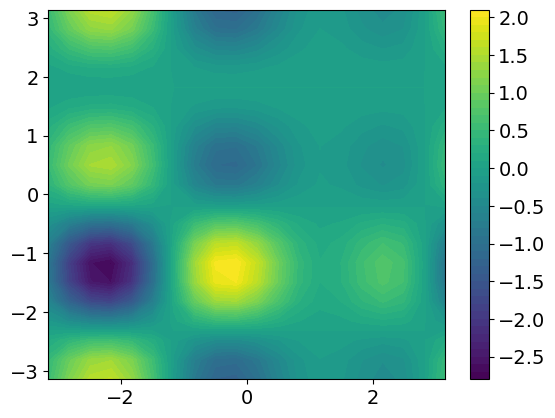

In [8]:
xtest=np.random.rand(10,1)
ytest=np.random.rand(10,1)

amplitudes = 0.5*np.random.rand(10,max_waves) + 0.5
phasesX = 2*np.pi*np.random.rand(10,max_waves)
phasesY = 2*np.pi*np.random.rand(10,max_waves)

# test = u0v(xtest,ytest,amplitudes,phasesX,phasesY)
# print(test.shape)

amplitudes = 0.5*np.random.rand(2,max_waves) + 0.5
phasesX = 2*np.pi*np.random.rand(2,max_waves)
phasesY = 2*np.pi*np.random.rand(2,max_waves)

test = u02d(X_b,Y_b,amplitudes,phasesX,phasesY)
print(test.shape)
plt.contourf(X_b,Y_b,test[0,],50)
plt.colorbar()

In [9]:
def defineCollocationPoints(N_pde, max_waves):

  # Uniform random sampling for PDE points
  txy_min = np.array([t0, xleft, ylower])
  txy_max = np.array([tfinal, xright, yupper])
  pde_points = txy_min + (txy_max - txy_min)*lhs(3, N_pde)
  t_pde = pde_points[:, 0]
  x_pde = pde_points[:, 1]
  y_pde = pde_points[:, 2]

  pdes = np.column_stack([t_pde, x_pde, y_pde])#.astype(np.float32)

  # Initial data sample
  x_points = np.linspace(xleft, xright, N_sensor_points)
  y_points = np.linspace(ylower, yupper, N_sensor_points)

  [x_points, y_points] = np.meshgrid(x_points, y_points, indexing='ij')
  t_points = 0*x_points

  amplitudes = 0.5*np.random.rand(N_pde,max_waves) + 0.5
  phasesX = 2*np.pi*np.random.rand(N_pde,max_waves)
  phasesY = 2*np.pi*np.random.rand(N_pde,max_waves)


  return (pdes, amplitudes, phasesX,phasesY)

def defineCollocationPoints1(N_pde=10000, N_u=100, max_waves=5):

  # Uniform random sampling for PDE points
  txy_min = np.array([t0, xleft, ylower])
  txy_max = np.array([tfinal, xright, yupper])
  pde_points = txy_min + (txy_max - txy_min)*lhs(3, N_pde)
  t_pde = pde_points[:, 0]
  x_pde = pde_points[:, 1]
  y_pde = pde_points[:, 2]

  pdes = np.column_stack([t_pde, x_pde, y_pde]).astype(np.float32)

  # Initial data sample
  x_points = np.linspace(xleft, xright, N_sensor_points)
  y_points = np.linspace(ylower, yupper, N_sensor_points)

  [x_points, y_points] = np.meshgrid(x_points, y_points, indexing='ij')
  t_points = 0*x_points

  usensors = []
  waveData = []

  for i in range(N_u):

    amplitudes = 0.5*np.random.rand(max_waves) + 0.5
    phasesX = 2*np.pi*np.random.rand(max_waves)
    phasesY = 2*np.pi*np.random.rand(max_waves)

    # Generate the data for the branch net
    u0curr = u0(x_points, y_points, amplitudes, phasesX, phasesY)

    # Generate the data for the trunk net
    usensors.append(np.expand_dims(u0curr, axis=0))
    waveData.append(np.expand_dims(np.concatenate([amplitudes, phasesX, phasesY]), axis=0))

  usensors = np.concatenate(usensors).astype(np.float32)
  waveData = np.concatenate(waveData).astype(np.float32)

  return (pdes, usensors, waveData)

In [10]:
#N_pde, N_u = 10000, 50
#(pdes, usensors, waveData) = defineCollocationPoints(N_pde, N_u, max_waves)
N_pde =100000
(pdes,amplitudes, phasesX,phasesY)=defineCollocationPoints(N_pde, max_waves)

### DeepONet model

In [11]:
class PeriodicBCs(tf.keras.layers.Layer):
  def __init__(self, name=None, **kwargs):
    super(PeriodicBCs, self).__init__(name=name, **kwargs)

  def call(self, inputs):
    return tf.concat((tf.cos(inputs), tf.sin(inputs)), axis=1)


# Define the normalization layer
class Normalize(tf.keras.layers.Layer):
  def __init__(self, xmin, xmax, name=None, **kwargs):
    super(Normalize, self).__init__(name=name)
    self.xmin = xmin
    self.xmax = xmax
    super(Normalize, self).__init__(**kwargs)

  def call(self, inputs):
    return 2.0*(inputs-self.xmin)/(self.xmax-self.xmin)-1.0

  def get_config(self):
    config = super(Normalize, self).get_config()
    config.update({'xmin': self.xmin, 'xmax': self.xmax})
    return config

In [12]:
def cnn_network(inp, n_layers, n_filters, strides, n_units):

  h = tf.keras.layers.Reshape((N_sensor_points, N_sensor_points, 1))(inp)
  for i in range(n_layers-1):
    h = tf.keras.layers.Conv2D(2**i*n_filters, 3, strides=strides, activation='tanh', padding='same')(h)
  h = tf.keras.layers.Flatten()(h)
  out = tf.keras.layers.Dense(n_units, activation='linear')(h)
  return out

In [13]:
def mlp_network(inp, n_layers, n_units):

  h = inp
  for i in range(n_layers-1):
    h = tf.keras.layers.Dense(n_units, activation='tanh')(h)
  out = tf.keras.layers.Dense(n_units, activation='linear')(h)
  return out

In [14]:
# Architecture
n_units = 60
n_layers = 8

n_layers_cnn = 4
n_filters = 16
strides = 2

# Branch net
inp_u = tf.keras.layers.Input(shape=(N_sensor_points, N_sensor_points, ))
branch_net = cnn_network(inp_u, n_layers_cnn, n_filters, strides, n_units)

# Trunk net
inp_t = tf.keras.layers.Input(shape=(1,))
b_t = Normalize(t0, tfinal)(inp_t)

inp_x = tf.keras.layers.Input(shape=(1,))
periodic_x = PeriodicBCs()(inp_x)

inp_y = tf.keras.layers.Input(shape=(1,))
periodic_y = PeriodicBCs()(inp_y)

inp_tx = tf.keras.layers.Concatenate()([b_t, periodic_x, periodic_y])

# Actual trunk net
trunk_net = mlp_network(inp_tx, n_layers, n_units)

out = tf.keras.layers.Multiply()([branch_net, trunk_net])
out = tf.keras.layers.Dense(1)(out)

model = tf.keras.models.Model([inp_t, inp_x, inp_y, inp_u], out)
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_2 (InputLayer)        [(None, 1)]                  0         []                            
                                                                                                  
 input_3 (InputLayer)        [(None, 1)]                  0         []                            
                                                                                                  
 input_4 (InputLayer)        [(None, 1)]                  0         []                            
                                                                                                  
 normalize_1 (Normalize)     (None, 1)                    0         ['input_2[0][0]']             
                                                                                              

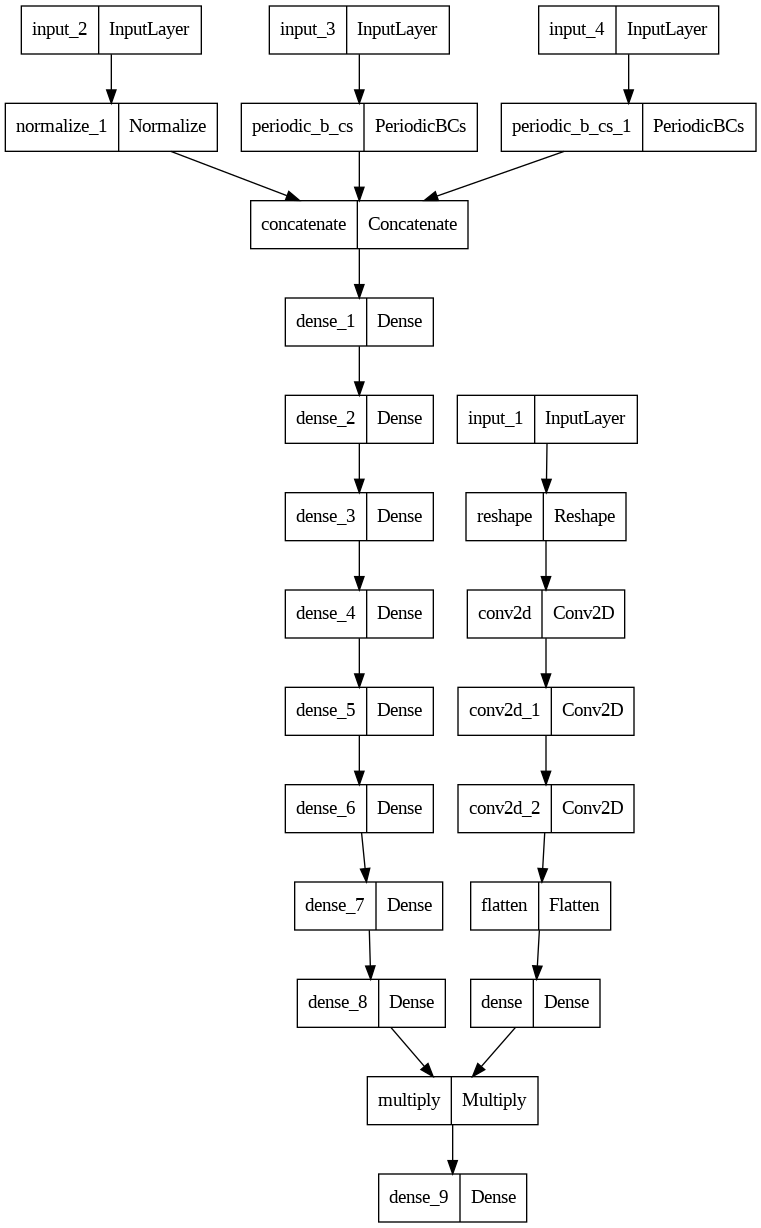

In [15]:
tf.keras.utils.plot_model(model)

In [54]:
@tf.function(reduce_retracing=True)
def train_network(pdes, a, pX, pY, opt):

  # PDE points
  t, x, y = pdes[:,:1], pdes[:,1:2], pdes[:,2:3]

  # Outer gradient for tuning network parameters
  with tf.GradientTape() as tape:

    with tf.GradientTape() as tape1:
      tape1.watch(t), tape1.watch(x), tape1.watch(y)
      u = u01d(x, y, a, pX, pY) + t/tfinal*model([t, x, y, u02d(X_b,Y_b, a, pX, pY)])
    [ut, ux, uy] = tape1.gradient(u, [t, x, y])

    # Linear advection equation
    eqn = ut + ux + uy

    # Loss
    loss = tf.reduce_mean(tf.square(eqn))

  # Model gradients and update
  grads = tape.gradient(loss, model.trainable_variables)

  opt.apply_gradients(zip(grads, model.trainable_variables))

  return loss

In [55]:
def trainDeepOnet(pde_points,amplitudes, phasesX,phasesY, epochs=10000):

  # Number of ICs and total number of PDE collocation points
  N_u = pde_points.shape[0]
  N_pde_points = pde_points.shape[1]

  # Batch size for PDE points
  batch_factor = 10000

  # Batch size for initial conditions

  ds_pde = tf.data.Dataset.from_tensor_slices(pde_points)
  ds_a = tf.data.Dataset.from_tensor_slices(amplitudes)
  ds_px = tf.data.Dataset.from_tensor_slices(phasesX)
  ds_py = tf.data.Dataset.from_tensor_slices(phasesY)

  ds = tf.data.Dataset.zip((ds_pde, ds_a,ds_px,ds_py))
  ds = ds.cache().shuffle(N_u).batch(batch_factor)
  ds = ds.prefetch(tf.data.experimental.AUTOTUNE)

  # Optimizer and learning rate to be used
  #lr = 1e-3
  #opt = tf.keras.optimizers.Adam(lr)

  lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
        1.2e-2, decay_steps = 200, decay_rate = 0.95, staircase=False)
  opt = tf.keras.optimizers.Adam(lr_schedule, beta_1 = 0.95, beta_2 = 0.99)

  epoch_loss = np.zeros(epochs)

  # Main training loop
  for i in range(epochs):

    nr_batches = 0

    # Training for that epoch
    for (bs_pdes, bs_a,bs_px,bs_py) in ds:


      # Train the network
      loss = train_network(bs_pdes,bs_a,bs_px,bs_py, opt)
      # loss = train_network(pdes, sensorData, opt)

      epoch_loss[i] += loss
      nr_batches += 1

    # Get total epoch loss
    epoch_loss[i] /= nr_batches

    if (np.mod(i, 100)==0):
      print(f"Total loss {i}th epoch: {epoch_loss[i]: 6.5f}.")

  return epoch_loss

In [56]:
epochs = 500
loss = trainDeepOnet(pdes,amplitudes, phasesX,phasesY, epochs)

Total loss 0th epoch:  2.95113.
Total loss 100th epoch:  0.00811.
Total loss 200th epoch:  0.00503.
Total loss 300th epoch:  0.00370.
Total loss 400th epoch:  0.00162.


In [ ]:
# Total loss 0th epoch:  2.95113.
# Total loss 100th epoch:  0.00811.
# Total loss 200th epoch:  0.00503.
# Total loss 300th epoch:  0.00370.
# Total loss 400th epoch:  0.00162.

In [57]:
#model.save('2d_adv_hard')

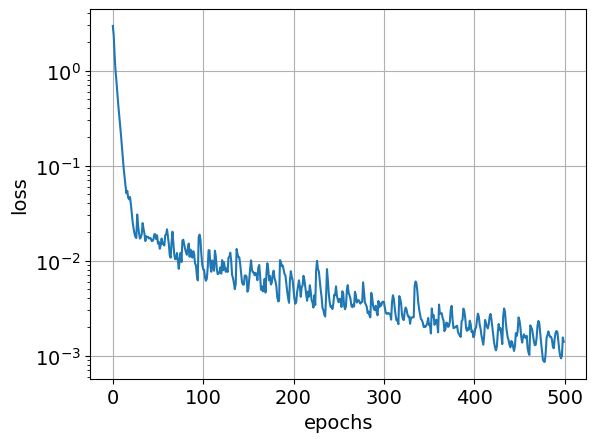

In [58]:
plt.semilogy(range(0, epochs), loss)
plt.xlabel('epochs')
plt.ylabel('loss')
plt.grid()

In [59]:
# Grid where to evaluate the model
l, m, n = 10, N_sensor_points, N_sensor_points
t_e = np.linspace(t0, tfinal, l)
x_e = np.linspace(xleft, xright, m)
y_e = np.linspace(ylower, yupper, n)
T_e, X_e, Y_e  = np.meshgrid(t_e, x_e, y_e, indexing='ij')

In [60]:
# Sample a new IC
amplitudes_e = 0.5*np.random.rand(1,max_waves) + 0.5
phasesX_e = 2*np.pi*np.random.rand(1,max_waves)
phasesY_e = 2*np.pi*np.random.rand(1,max_waves)

x_points_e = np.linspace(xleft, xright, N_sensor_points)
y_points_e = np.linspace(ylower, yupper, N_sensor_points)
[x_points_e, y_points_e] = np.meshgrid(x_points_e, y_points_e, indexing='ij')
usensor = u02d(x_points_e, y_points_e, amplitudes_e, phasesX_e, phasesY_e)

#usensor = np.expand_dims(u0curr, axis=0)

u = model([np.expand_dims(T_e.flatten(), axis=1),
           np.expand_dims(X_e.flatten(), axis=1),
           np.expand_dims(Y_e.flatten(), axis=1),
           usensor])[:,0]
u = u01d(X_e.flatten(), Y_e.flatten(), amplitudes_e, phasesX_e, phasesY_e) + T_e.flatten()/tfinal*u.numpy()

u = np.reshape(u, T_e.shape)

In [61]:
#uTrue = u0ref(X-T, Y-T, amplitudes[0,], phasesX[0,], phasesY[0,])
uTrue = np.reshape(u01d(X_e.flatten()-T_e.flatten(), Y_e.flatten()-T_e.flatten(), amplitudes_e, phasesX_e, phasesY_e), T_e.shape)

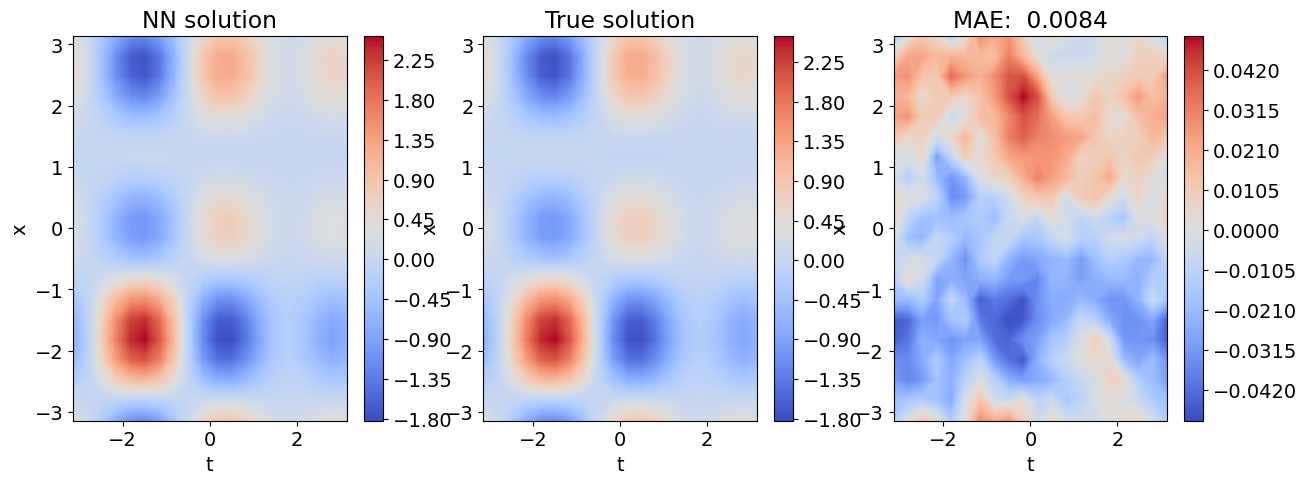

In [62]:
plt.figure(figsize=(15,5))
plt.subplot(131)

plt.contourf(X_e[-1,], Y_e[-1,], u[-1,], 200, cmap=plt.cm.coolwarm)
plt.xlabel('t')
plt.ylabel('x')
plt.title('NN solution')
plt.colorbar()


plt.subplot(132)
plt.contourf(X_e[-1,], Y_e[-1,], uTrue[-1,], 200, cmap=plt.cm.coolwarm)
plt.xlabel('t')
plt.ylabel('x')
plt.title('True solution')
plt.colorbar()

plt.subplot(133)
plt.contourf(X_e[-1,], Y_e[-1,], u[-1,]-uTrue[-1,], 200, cmap=plt.cm.coolwarm)
plt.xlabel('t')
plt.ylabel('x')
plt.title(f'MAE: {tf.reduce_mean(tf.abs(u-uTrue)): 2.4f}')
plt.colorbar()

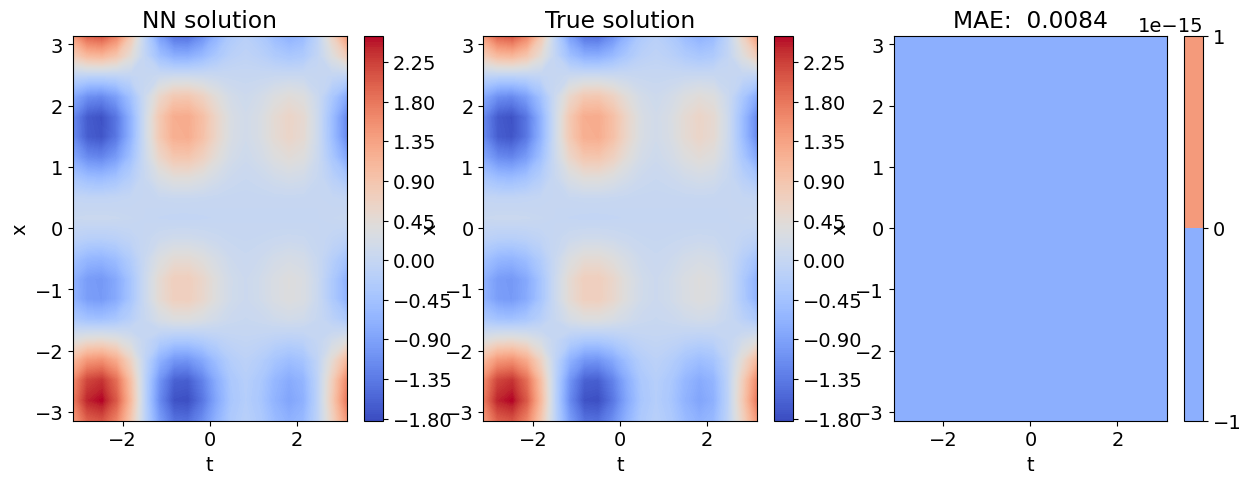

In [63]:
plt.figure(figsize=(15,5))
plt.subplot(131)

plt.contourf(X_e[0,], Y_e[0,], u[0,], 200, cmap=plt.cm.coolwarm)
plt.xlabel('t')
plt.ylabel('x')
plt.title('NN solution')
plt.colorbar()


plt.subplot(132)
plt.contourf(X_e[0,], Y_e[0,], uTrue[0,], 200, cmap=plt.cm.coolwarm)
plt.xlabel('t')
plt.ylabel('x')
plt.title('True solution')
plt.colorbar()

plt.subplot(133)
plt.contourf(X_e[0,], Y_e[0,], u[0,]-uTrue[0,], 200, cmap=plt.cm.coolwarm)
plt.xlabel('t')
plt.ylabel('x')
plt.title(f'MAE: {tf.reduce_mean(tf.abs(u-uTrue)): 2.4f}')
plt.colorbar()

In [64]:
u1d_test=u01d(X_e.flatten(), Y_e.flatten(), amplitudes_e, phasesX_e, phasesY_e)
print(u1d_test.shape)
u2d_test=np.reshape(u1d_test,X_e.shape)
print(u2d_test.shape)

(1, 4000)
(10, 20, 20)


In [65]:
u2d_test_rec=uTrue[0,]
print(u2d_test_rec.shape)
print(np.max(u2d_test[1,]-u2d_test_rec))
uinit=np.repeat(u2d_test_rec[None,],l,axis=0)
print(uinit.shape)
print(np.max(u2d_test-uinit))

print(np.max(u1d_test-uinit.flatten()))

(20, 20)
0.0
(10, 20, 20)
0.0
0.0


### Time stepping with DeepOnet

In [66]:
steps = 50

In [67]:
uinit = u01d(X_e.flatten(), Y_e.flatten(), amplitudes_e, phasesX_e, phasesY_e)
usensor = u02d(x_points_e, y_points_e, amplitudes_e, phasesX_e, phasesY_e)
print(uinit.shape)
print(usensor.shape)

(1, 4000)
(1, 20, 20)


In [68]:
uinit = u01d(X_e.flatten(), Y_e.flatten(), amplitudes_e, phasesX_e, phasesY_e)


In [69]:
T_e[0,].max()

0.0

In [70]:
uinit = u01d(X_e.flatten(), Y_e.flatten(), amplitudes_e, phasesX_e, phasesY_e)
usensor = u02d(x_points_e, y_points_e, amplitudes_e, phasesX_e, phasesY_e)



u = []
for i in range(steps):

  u_c = model([np.expand_dims(T_e.flatten(), axis=1),
           np.expand_dims(X_e.flatten(), axis=1),
           np.expand_dims(Y_e.flatten(), axis=1),
           usensor])[:,0]
  u_c =  uinit + T_e.flatten()/tfinal*u_c.numpy()

  u_c = np.reshape(u_c, T_e.shape)
  #print(np.max(u_c[0,]-uinit.numpy().reshape(T_e.shape)[0,]))
  if i==0:
    u.append(u_c)
  else:
    u.append(u_c[1:,])


  uinit=np.repeat(u_c[None,-1,:,:],l,axis=0).flatten()#np.repeat(u_c[-1,],l).flatten()
  usensor=u_c[None,-1,]

u = np.concatenate(u)
#print(u.shape)
#print(u_c.shape)

In [71]:
# Exact solution
#t_all = np.linspace(t0, steps*tfinal, u.shape[0])#steps*l)
t_all = np.linspace(t0, steps*tfinal, u.shape[0])
T_all, X_all, Y_all  = np.meshgrid(t_all, x_e, y_e, indexing='ij')


uTrue = np.reshape(u01d(X_all.flatten()-T_all.flatten(), Y_all.flatten()-T_all.flatten(), amplitudes_e, phasesX_e, phasesY_e), T_all.shape)

In [72]:
uTrue.shape

(451, 20, 20)

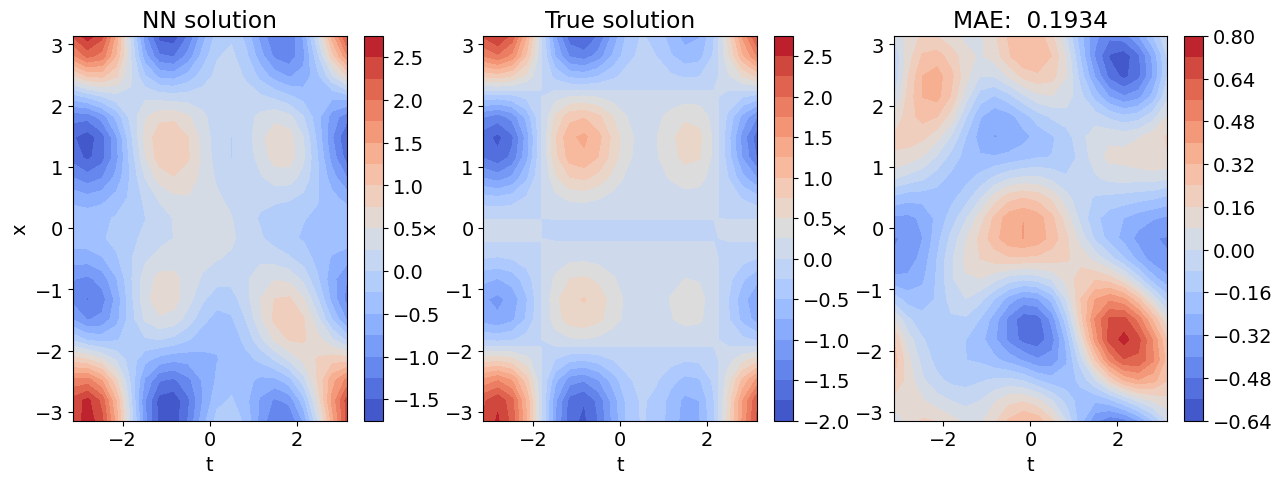

In [73]:
plt.figure(figsize=(15,5))
plt.subplot(131)

id_t=-1

plt.contourf(X_all[0,],Y_all[0,], u[id_t,], 20, cmap=plt.cm.coolwarm)
plt.xlabel('t')
plt.ylabel('x')
plt.title('NN solution')
plt.colorbar()


plt.subplot(132)
plt.contourf(X_all[0,],Y_all[0,], uTrue[id_t,], 20, cmap=plt.cm.coolwarm)
plt.xlabel('t')
plt.ylabel('x')
plt.title('True solution')
plt.colorbar()

plt.subplot(133)
plt.contourf(X_all[0,],Y_all[0,], u[id_t,]-uTrue[id_t,], 20, cmap=plt.cm.coolwarm)
plt.xlabel('t')
plt.ylabel('x')
plt.title(f'MAE: {tf.reduce_mean(tf.abs(u[id_t,]-uTrue[id_t,])): 2.4f}')
plt.colorbar()

In [74]:
uTrue.shape

(451, 20, 20)

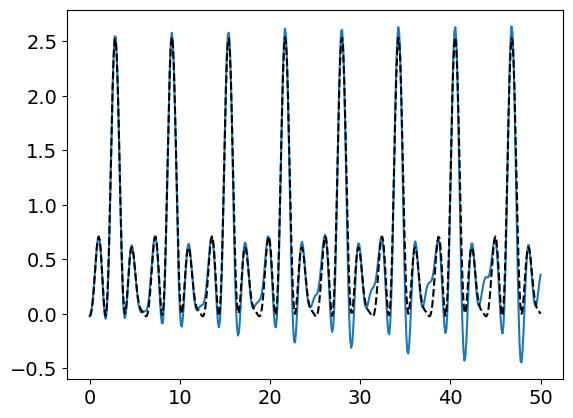

In [75]:
plt.plot(t_all, u[:,10,10])
plt.plot(t_all, uTrue[:,10,10],'k--')


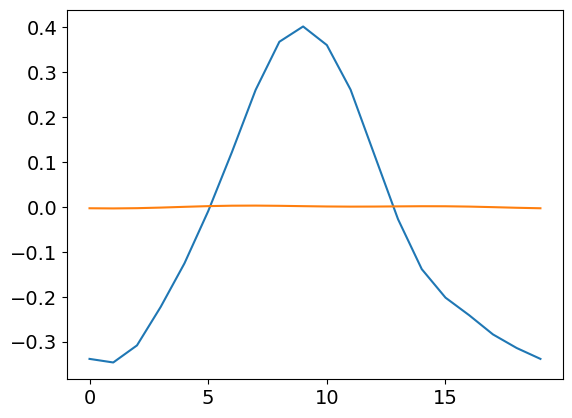

In [76]:
plt.plot(u[-1,:,10])
plt.plot(uTrue[-1,:,10])